# Fraud Detection in Electricity and Gas Consumption

Team project based on the Zindi challenge
[Fraud Detection in Electricity and Gas Consumption](https://zindi.africa/competitions/fraud-detection-in-electricity-and-gas-consumption-challenge).
The notebook follows the 7-stage ML blueprint:

1. Data Ingestion & Problem Framing
2. Train/Test Split & EDA Light
3. Cleaning & Feature Preprocessing
4. Baselines & Feature Selection
5. Model Exploration & CV
6. Diagnostics, Plots & Interpretability
7. Business Alignment & Turning Points

# Stage 1: Data Ingestion & Problem Framing

### Data

| File | Grain | Content |
| --- | --- | --- |
| `client_train.csv` / `client_test.csv` | one row per client | district, region, client category, creation date, **target** (train only) |
| `invoice_train.csv` / `invoice_test.csv` | one row per invoice | date, tariff, counter info, consumption levels 1–4, meter indices, counter type (ELEC/GAZ) |

The Zindi test set has no labels: it is only used for the submission, we evaluate on our own holdout.

## 1.1 Loading and overview the data (first look)

In [ ]:
# Imports
from pathlib import Path
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd


In [ ]:
# Load the raw tables
client_train = pd.read_csv("data/train/client_train.csv")
invoice_train = pd.read_csv("data/train/invoice_train.csv", low_memory=False)
client_test = pd.read_csv("data/test/client_test.csv")
invoice_test = pd.read_csv("data/test/invoice_test.csv", low_memory=False)
submission = pd.read_csv("data/output/submission.csv")

for name, df in {
    "client_train": client_train,
    "invoice_train": invoice_train,
    "client_test": client_test,
    "invoice_test": invoice_test,
    "submission": submission,
}.items():
    print(f"{name:14s} {df.shape}")


In [ ]:
# First look: client tables
print(client_train.head())
print(client_test.head(10))
display(client_train.describe().T)
# print(client_train["target"].value_counts().sum())
print("This is the fraud percantage")
print(client_train["target"].mean()*100)

   disrict          client_id  client_catg  region creation_date  target
0       60     train_Client_0           11     101    31/12/1994     0.0
1       69     train_Client_1           11     107    29/05/2002     0.0
2       62    train_Client_10           11     301    13/03/1986     0.0
3       69   train_Client_100           11     105    11/07/1996     0.0
4       62  train_Client_1000           11     303    14/10/2014     0.0
   disrict          client_id  client_catg  region creation_date
0       62      test_Client_0           11     307    28/05/2002
1       69      test_Client_1           11     103    06/08/2009
2       62     test_Client_10           11     310    07/04/2004
3       60    test_Client_100           11     101    08/10/1992
4       62   test_Client_1000           11     301    21/07/1977
5       62  test_Client_10000           11     304    18/02/2015
6       62  test_Client_10001           11     303    13/09/2005
7       69  test_Client_10002           11

,count,mean,std,min,25%,50%,75%,max
disrict,135493.0,63.511222,3.354400,60.0,62.0,62.0,69.0,69.0
client_catg,135493.0,11.512506,4.423761,11.0,11.0,11.0,11.0,51.0
region,135493.0,206.159809,104.207044,101.0,103.0,107.0,307.0,399.0
target,135493.0,0.055841,0.229614,0.0,0.0,0.0,0.0,1.0


This is the fraud percantage
5.584052312665599


In [ ]:
# First look: invoice table
invoice_train.head(21)

In [ ]:
# Missing and zero values
print("Do we have NaN-values?: ")
print(invoice_train.isna().sum())

print("Do we have Values, that are 'zero'?:")
print((invoice_train == 0).sum())

## 1.2 Column overview

In [ ]:
# Column overview: client table
def overview(df):
    return pd.DataFrame({
        "dtype": df.dtypes,
        "n_unique": df.nunique(),
        "n_missing": df.isna().sum(),
        "example": df.iloc[0],
    })


overview(client_train)


,dtype,n_unique,n_missing,example
disrict,int64,4,0,60
client_id,str,135493,0,train_Client_0
client_catg,int64,3,0,11
region,int64,25,0,101
creation_date,str,8088,0,31/12/1994
target,float64,2,0,0.0


In [ ]:
# Column overview: invoice table
overview(invoice_train)

,dtype,n_unique,n_missing,example
client_id,str,135493,0,train_Client_0
invoice_date,str,8275,0,2014-03-24
tarif_type,int64,17,0,11
counter_number,int64,201893,0,1335667
counter_statue,str,12,0,0
counter_code,int64,42,0,203
reading_remarque,int64,8,0,8
counter_coefficient,int64,16,0,1
consommation_level_1,int64,8295,0,82
consommation_level_2,int64,12576,0,0


## 1.3 Join key and data grain

### What does it mean?

- **Data grain** = what one row stands for: in `client_train` one row is **one client**, in `invoice_train` one row is **one invoice**.
- **Join key** = the column that links both tables: `client_id`.
- One client has **many** invoices (1 : n). So before joining, the invoices must be summarised per client (one row per client). Otherwise every client would appear ~33 times, together with their `target`.

In [ ]:
# Join key and data grain
print("Each client appears only once:", client_train["client_id"].is_unique)
print("Invoices without a known client:", (~invoice_train["client_id"].isin(client_train["client_id"])).sum())
print("Clients without any invoice:", (~client_train["client_id"].isin(invoice_train["client_id"])).sum())

# How many invoices does one client have?
invoice_train.groupby("client_id").size().describe()

Each client appears only once: True
Invoices without a known client: 0
Clients without any invoice: 0


count    135493.000000
mean         33.040445
std          26.092229
min           1.000000
25%          10.000000
50%          30.000000
75%          50.000000
max         439.000000
dtype: float64

## 1.4 Target distribution

target
0.0    127927
1.0      7566
Name: count, dtype: int64

target
0.0    94.4
1.0     5.6
Name: proportion, dtype: float64


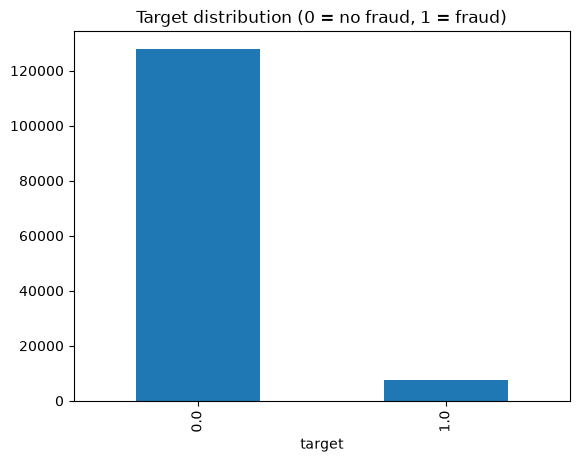

In [ ]:
# Target distribution
print(client_train["target"].value_counts(dropna=False))
print()
print(client_train["target"].value_counts(normalize=True).round(3)*100)

client_train["target"].value_counts().plot.bar(title="Target distribution (0 = no fraud, 1 = fraud)")
plt.show()


# Stage 1 End: Results & Learnings (Marker)

## 1.5 Problem Framing

### Stakeholder, goal and metric

**Stakeholder:** STEG (Tunisian Company of Electricity and Gas), revenue protection / inspection teams.

**Problem:** Some customers manipulate their electricity or gas meters, which causes large revenue losses.
On-site inspections are expensive and capacity is limited, so STEG cannot check every customer.

**Goal:** Rank customers by their probability of fraud, based on their client data and billing history,
so inspection teams visit the most suspicious customers first.

**ML task:** Binary classification at client level.
- Target `y`: `target` in `client_train.csv` (1 = fraud, 0 = no fraud), one label per client
- Signal: ~4.5 M invoices in `invoice_train.csv`, aggregated per `client_id`
- Class imbalance: 5.6 % fraud

**Metrics:**
- **Zindi:** ROC-AUC (competition metric). It measures how well the model ranks fraud above non-fraud, without a threshold.
- **Business:** Recall & F2 at the chosen threshold. A missed fraud case means lost revenue, so recall matters most;
  F2 weights recall higher but still punishes flagging everyone as fraud.
- Accuracy is useless here: predicting "never fraud" already reaches 94.4 % and finds no fraud at all.

### Rubber-duck checklist

- [x] **Do we know exactly what the target $y$ is?** → Yes: `target` in `client_train.csv`, one label per client.
- [x] **Regression, classification, clustering or anomaly detection?** → Binary classification, output as fraud probability for ranking.
- [x] **Do all features exist at prediction time?** → Not fully verifiable: the data has no fraud-detection date. Invoices issued after detection (counter replacement, corrections) could leak the label. Risk noted; check in Stage 2 (end of invoice history, fraud vs. non-fraud) and Stage 6 (suspiciously dominant features).

## 1.6 Learnings (Marker)

### Stage 1: Marker – Problem type first, then algorithm and metric

Three separate levels:

1. **Problem type:** what should come out? Decided only by what $y$ looks like, and whether there is a $y$ at all.
2. **Algorithm:** what do I compute with? (e.g. Decision Tree, LightGBM)
3. **Metric:** how do I measure if it is good? (e.g. Accuracy, Recall, RMSE)

| Problem type | $y$ looks like | Question | Example metric | Example algorithm |
| --- | --- | --- | --- | --- |
| **Regression** | a number, e.g. 1,234 kWh | How much? | RMSE, MAE | Linear Regression, Decision Tree |
| **Classification** | a class, e.g. 0/1 | Which group? | Accuracy, Recall, Precision, F1, AUC | Logistic Regression, Decision Tree |
| **Clustering** | **no $y$** | Which clients are similar? | Silhouette score | k-Means |
| **Anomaly detection** | **no $y$** (or almost none) | Who is unusual? | Precision@k | Isolation Forest |

- Accuracy is a classification metric; regression measures the distance to the true number (RMSE).
- A Decision Tree is an algorithm, not a problem type: it does regression and classification, not clustering.
- Recall and Precision count false positives/negatives, so they need the true answer (labels).
- Fraud is often an anomaly-detection problem, namely when nobody knows which clients committed fraud.

# Stage 2: Data Splitting & EDA Light

### Split strategy

- **What is split:** the clients in `client_train` (one row = one client = one `target`). The invoices follow their client via `client_id`, so all invoices of a client stay on the same side.
- **Why not split the invoices:** the same client (and their `target`) would end up in train and holdout → data leakage.
- **Stratified:** `stratify=y` keeps the fraud rate (5.6 %) equal in train and holdout.
- **No time-based split:** the `target` has no date (one label per client), so there is no "past vs. future" of clients.
- **Holdout (20 %)** stays untouched until the final evaluation in Stage 7. All EDA below uses the train part only.

## 2.1 Train/holdout split at client level

In [ ]:
# Stratified train/holdout split at client level
from sklearn.model_selection import train_test_split

train_clients, holdout_clients = train_test_split(
    client_train,
    test_size=0.2,
    stratify=client_train["target"],
    random_state=42,
)

print("train  :", train_clients.shape, f"fraud rate {train_clients['target'].mean():.2%}")
print("holdout:", holdout_clients.shape, f"fraud rate {holdout_clients['target'].mean():.2%}")

train  : (108394, 6) fraud rate 5.58%
holdout: (27099, 6) fraud rate 5.58%


In [ ]:
# Invoices follow their client
train_invoices = invoice_train[invoice_train["client_id"].isin(train_clients["client_id"])]
holdout_invoices = invoice_train[invoice_train["client_id"].isin(holdout_clients["client_id"])]

print("train invoices  :", train_invoices.shape)
print("holdout invoices:", holdout_invoices.shape)
print("clients on both sides:", len(set(train_invoices["client_id"]) & set(holdout_invoices["client_id"])))

train invoices  : (3590916, 16)
holdout invoices: (885833, 16)
clients on both sides: 0


In [ ]:
# Save holdout client IDs so the whole team uses the same split
Path("data/split").mkdir(exist_ok=True)
holdout_clients[["client_id"]].to_csv("data/split/holdout_ids.csv", index=False)

## 2.2 Leakage check: end of the invoice history

### Why this check?

The data has no fraud-detection date (Stage 1, checklist). If STEG replaces the counter or corrects invoices **after** detecting a fraud, fraud clients look different at the **end** of their history.
A large difference is a warning sign for leakage; a small one does not prove there is none.

In [ ]:
# Leakage check: do fraud clients look different at the end of their history? (train only)
inv = train_invoices.copy()
inv["invoice_date"] = pd.to_datetime(inv["invoice_date"])

per_client = inv.groupby("client_id").agg(
    last_invoice=("invoice_date", "max"),
    n_counters=("counter_number", "nunique"),
).join(train_clients.set_index("client_id")["target"])

per_client.groupby("target").agg(
    median_last_invoice=("last_invoice", "median"),
    mean_n_counters=("n_counters", "mean"),
)

,median_last_invoice,mean_n_counters
target,,
0.0,2019-05-07,1.665540
1.0,2019-05-20,2.313068


# Stage 2 End: Results & Learnings (Marker)

## 2.3 Split decisions

### Rubber-duck checklist

- [x] **Was the test set split off before any deeper analysis/scaling?** → Yes: 20 % holdout of `client_train`, split at client level before EDA.
- [x] **Is there a time dimension in the data?** → Invoices have dates, but the `target` has none (one label per client) → stratified random split at client level is valid.
- [x] **Is the target class extremely imbalanced?** → Yes, 5.6 % fraud → `stratify=y`.

## 2.4 Learnings (Marker)